In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
col = pd.DataFrame({'color':['white','red','green','red','green'],
                   'object':['pen','pencil','pencil','ash','pen'],
                   'price1':[5,4,3,2,1],
                   'price2':[4.7,4.5,1.2,2.1,6.7]})
col

,color,object,price1,price2
0,white,pen,5,4.7
1,red,pencil,4,4.5
2,green,pencil,3,1.2
3,red,ash,2,2.1
4,green,pen,1,6.7


In [4]:
col.groupby(['color'],as_index=False)['price2'].mean() # 按颜色分组 聚合函数mean()

,color,price2
0,green,3.95
1,red,3.30
2,white,4.70


In [8]:
# index设置为True的结果
col.groupby(['color'],as_index=True)['price2'].mean()

color
green    3.95
red      3.30
white    4.70
Name: price2, dtype: float64

In [7]:
# 分组 聚合后取其中的数值  用[]来取值
col.groupby(['color'],as_index=True)['price2'].mean()['green']

3.95

In [10]:
# 上面的也可以用下面的方式来分组 聚合
col['price2'].groupby(col['color']).mean()

color
green    3.95
red      3.30
white    4.70
Name: price2, dtype: float64

In [5]:
# 星巴克案例
starbucks = pd.read_csv('directory.csv')
starbucks.head()

,Brand,Store Number,Store Name,Ownership Type,Street Address,City,State/Province,Country,Postcode,Phone Number,Timezone,Longitude,Latitude
0,Starbucks,47370-257954,"Meritxell, 96",Licensed,"Av. Meritxell, 96",Andorra la Vella,7,AD,AD500,376818720,GMT+1:00 Europe/Andorra,1.53,42.51
1,Starbucks,22331-212325,Ajman Drive Thru,Licensed,"1 Street 69, Al Jarf",Ajman,AJ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,55.47,25.42
2,Starbucks,47089-256771,Dana Mall,Licensed,Sheikh Khalifa Bin Zayed St.,Ajman,AJ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,55.47,25.39
3,Starbucks,22126-218024,Twofour 54,Licensed,Al Salam Street,Abu Dhabi,AZ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,54.38,24.48
4,Starbucks,17127-178586,Al Ain Tower,Licensed,"Khaldiya Area, Abu Dhabi Island",Abu Dhabi,AZ,AE,NaN,NaN,GMT+04:00 Asia/Dubai,54.54,24.51


In [6]:
star = starbucks.groupby(['Country']).count()   # 按国家分组 
star.head()

,Brand,Store Number,Store Name,Ownership Type,Street Address,City,State/Province,Postcode,Phone Number,Timezone,Longitude,Latitude
Country,,,,,,,,,,,,
AD,1,1,1,1,1,1,1,1,1,1,1,1
AE,144,144,144,144,144,144,144,24,78,144,144,144
AR,108,108,108,108,108,108,108,100,29,108,108,108
AT,18,18,18,18,18,18,18,18,17,18,18,18
AU,22,22,22,22,22,22,22,22,0,22,22,22


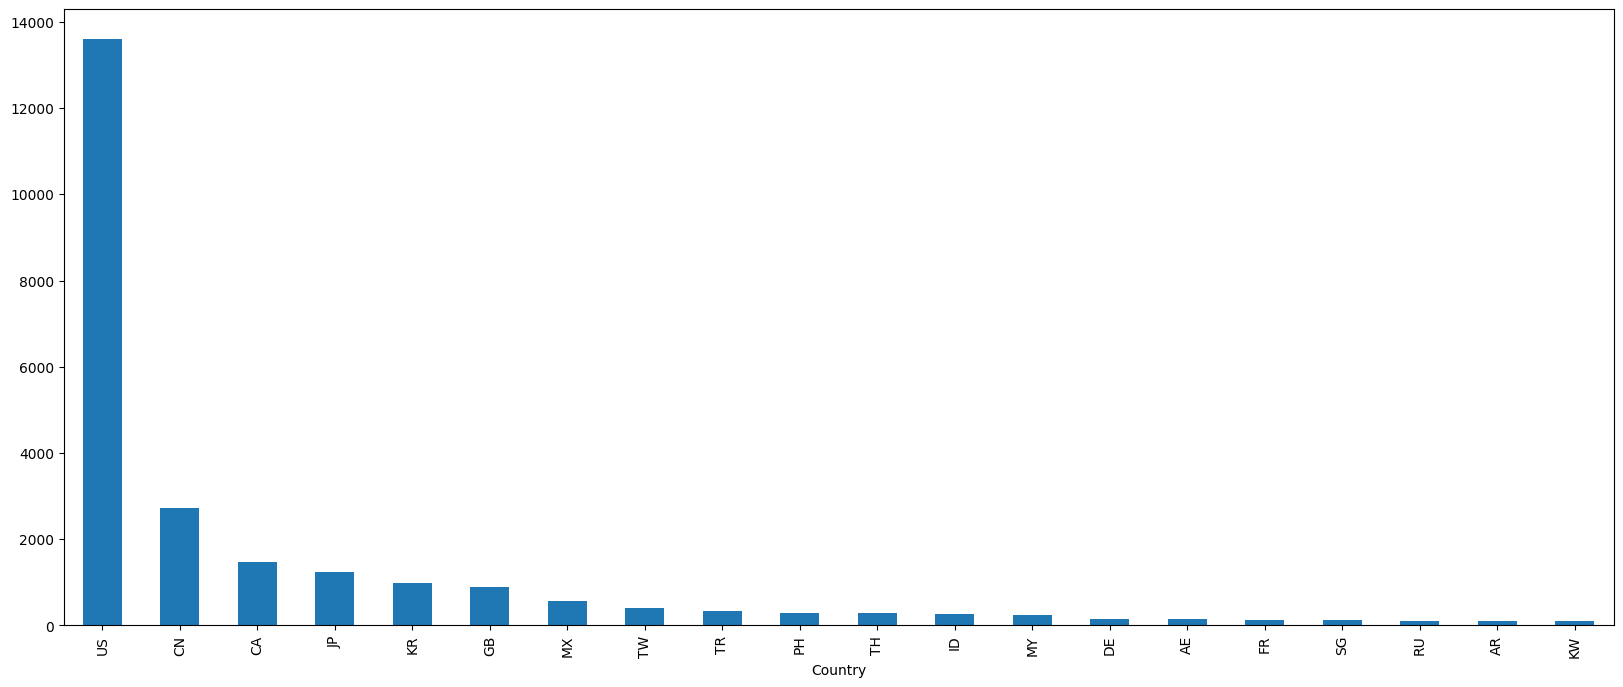

In [29]:
star['Brand'].sort_values(ascending=False)[:20].plot(figsize=(20,8),kind='bar')  # 只取前20的排名
plt.show()

In [7]:
# 设置多重索引分组   可以看出每个国家 每个州有多少店面
starbucks.groupby(['Country','State/Province']).count()

Brand  Store Number  Store Name  Ownership Type  \
Country State/Province                                                    
AD      7                   1             1           1               1   
AE      AJ                  2             2           2               2   
        AZ                 48            48          48              48   
        DU                 82            82          82              82   
        FU                  2             2           2               2   
...                       ...           ...         ...             ...   
US      WV                 25            25          25              25   
        WY                 23            23          23              23   
VN      HN                  6             6           6               6   
        SG                 19            19          19              19   
ZA      GT                  3             3           3               3   

                        Street Address  City  Postcode  Phone Number  \
Country State/Province                                                 
AD      7                            1     1         1             1   
AE      AJ                           2     2         0             0   
        AZ                          48    48         7            20   
        DU                          82    82        16            50   
        FU                           2     2         1             0   
...                                ...   ...       ...           ...   
US      WV                          25    25        25            23   
        WY                          23    23        23            22   
VN      HN                           6     6         6             6   
        SG                          19    19        19            17   
ZA      GT                           3     3         3             2   

                        Timezone  Longitude  Latitude  
Country State/Province                                 
AD      7                      1          1         1  
AE      AJ                     2          2         2  
        AZ                    48         48        48  
        DU                    82         82        82  
        FU                     2          2         2  
...                          ...        ...       ...  
US      WV                    25         25        25  
        WY                    23         23        23  
VN      HN                     6          6         6  
        SG                    19         19        19  
ZA      GT                     3          3         3  

[545 rows x 11 columns]